In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

df = pd.read_csv("../data/raw/creditcard.csv")

print("Dataset shape:", df.shape)

Dataset shape: (284807, 31)


In [3]:
print("Number of transactions:", len(df))
print("Number of features:", df.shape[1] - 1)
print("Target variable:", "Class")

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values:", df.isnull().sum().sum())

Number of transactions: 284807
Number of features: 30
Target variable: Class

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
float64    30
int64       1
Name: count, dtype: int64

Missing values: 0


In [4]:
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_groups = (
    duplicate_rows
    .groupby(list(df.columns), dropna=False)
    .size()
    .reset_index(name="frequency")
)

print("Rows belonging to duplicate groups:",
      len(duplicate_rows))

print("Unique duplicate groups:",
      len(duplicate_groups))

print("Excess duplicate occurrences:",
      (duplicate_groups["frequency"] - 1).sum())

print("\nDuplicate group frequencies:")
print(duplicate_groups["frequency"].value_counts().sort_index())

print("\nDuplicate groups by class:")
print(
    duplicate_groups.groupby("Class")["frequency"]
    .agg(["count", "sum"])
)

Rows belonging to duplicate groups: 1854
Unique duplicate groups: 773
Excess duplicate occurrences: 1081

Duplicate group frequencies:
frequency
2     611
3      66
4      81
5      10
6       1
9       2
18      2
Name: count, dtype: int64

Duplicate groups by class:
       count   sum
Class             
0        760  1822
1         13    32


In [5]:
fraud_duplicate_groups = duplicate_groups[
    duplicate_groups["Class"] == 1
]

print("Fraudulent duplicate groups:",
      len(fraud_duplicate_groups))

print("\nFraud duplicate group frequencies:")

print(
    fraud_duplicate_groups["frequency"]
    .value_counts()
    .sort_index()
)

display(
    fraud_duplicate_groups
    .sort_values("frequency", ascending=False)
)

Fraudulent duplicate groups: 13

Fraud duplicate group frequencies:
frequency
2    11
4     1
6     1
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,frequency
281,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1,6
437,94362.0,-26.457745,16.497472,-30.177317,8.904157,-17.892600,-1.227904,-31.197329,-11.438920,-9.462573,...,3.460893,0.896538,0.254836,-0.738097,-0.966564,-7.263482,-1.324884,1.00,1,4
393,84204.0,-1.927453,1.827621,-7.019495,5.348303,-2.739188,-2.107219,-5.015848,1.205868,-4.382713,...,-0.792017,-0.771414,-0.379574,0.718717,1.111151,1.277707,0.819081,512.25,1,2
394,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,...,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.00,1,2
398,85285.0,-7.030308,3.421991,-9.525072,5.270891,-4.024630,-2.865682,-6.989195,3.791551,-4.622730,...,-0.541855,0.036943,-0.355519,0.353634,1.042458,1.359516,-0.272188,0.00,1,2
399,85285.0,-6.713407,3.921104,-9.746678,5.148263,-5.151563,-2.099389,-5.937767,3.578780,-4.684952,...,-0.451086,0.127214,-0.339450,0.394096,1.075295,1.649906,-0.394905,252.92,1,2
429,93853.0,-6.185857,7.102985,-13.030455,8.010823,-7.885237,-3.974550,-12.229608,4.971232,-4.248307,...,0.481691,0.480958,0.360319,-0.293354,-0.199193,-0.203917,0.398927,44.90,1,2
430,93853.0,-5.839192,7.151532,-12.816760,7.031115,-9.651272,-2.938427,-11.543207,4.843627,-3.494276,...,1.054865,0.530481,0.472670,-0.275998,0.282435,0.104886,0.254417,316.06,1,2
431,93860.0,-10.850282,6.727466,-16.760583,8.425832,-10.252697,-4.192171,-14.077086,7.168288,-3.683242,...,0.135535,-1.023967,0.406265,0.106593,-0.026232,-1.464630,-0.411682,78.00,1,2
432,93860.0,-10.632375,7.251936,-17.681072,8.204144,-10.166591,-4.510344,-12.981606,6.783589,-4.659330,...,0.695603,-1.138122,0.459442,0.386337,0.522438,-1.416604,-0.488307,188.52,1,2


In [8]:
from pathlib import Path

FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory:", FIGURE_DIR.resolve())

Figure directory: /Users/jasmithav/isfe_creditcard_project/figures


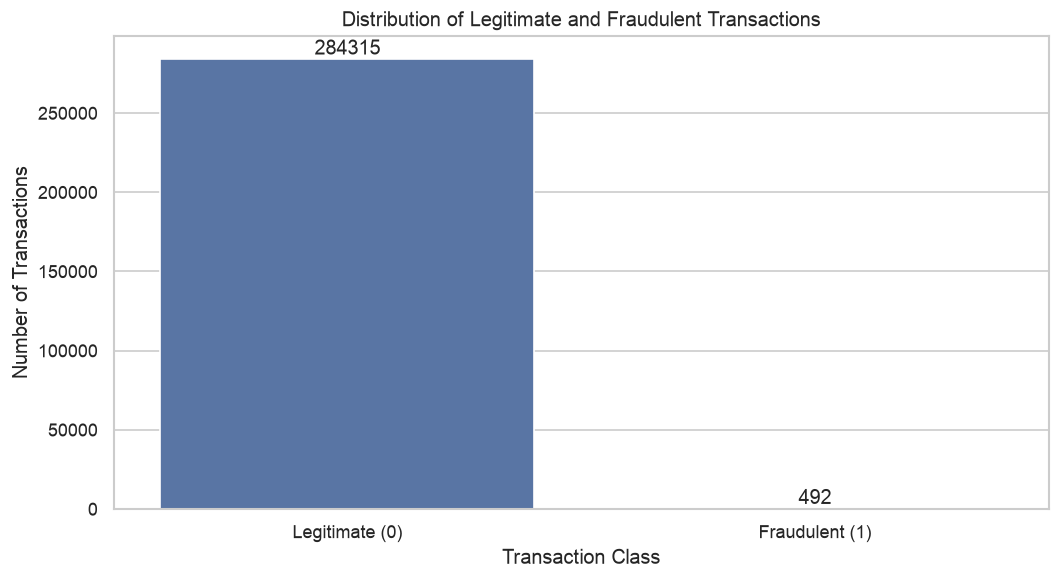

In [9]:
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=["Legitimate (0)", "Fraudulent (1)"],
    y=class_counts.values
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "class_distribution.png")
plt.show()

Class percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


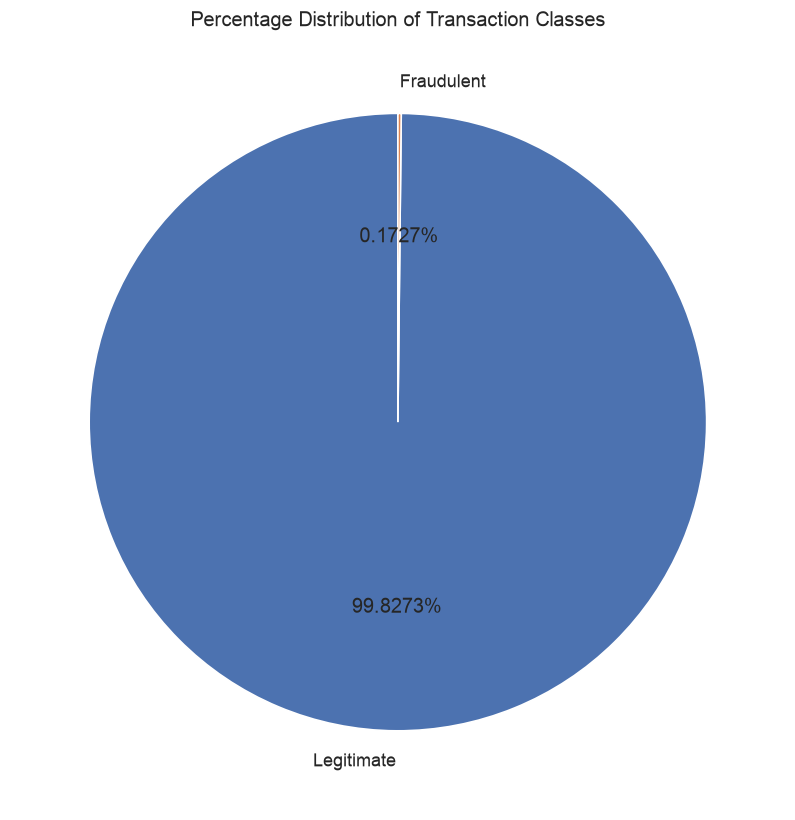

In [10]:
class_percentages = (
    df["Class"].value_counts(normalize=True) * 100
)

print("Class percentages:")
print(class_percentages)

plt.figure(figsize=(7, 7))

plt.pie(
    class_percentages.values,
    labels=["Legitimate", "Fraudulent"],
    autopct="%1.4f%%",
    startangle=90
)

plt.title("Percentage Distribution of Transaction Classes")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "class_percentage.png")
plt.show()

In [11]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [12]:
class_statistics = df.groupby("Class").agg({
    "Amount": ["mean", "median", "std", "min", "max"],
    "Time": ["mean", "median", "std", "min", "max"]
})

display(class_statistics)

Amount                                            Time           \
             mean median         std  min       max          mean   median   
Class                                                                        
0       88.291022  22.00  250.105092  0.0  25691.16  94838.202258  84711.0   
1      122.211321   9.25  256.683288  0.0   2125.87  80746.806911  75568.5   

                                      
                std    min       max  
Class                                 
0      47484.015786    0.0  172792.0  
1      47835.365138  406.0  170348.0

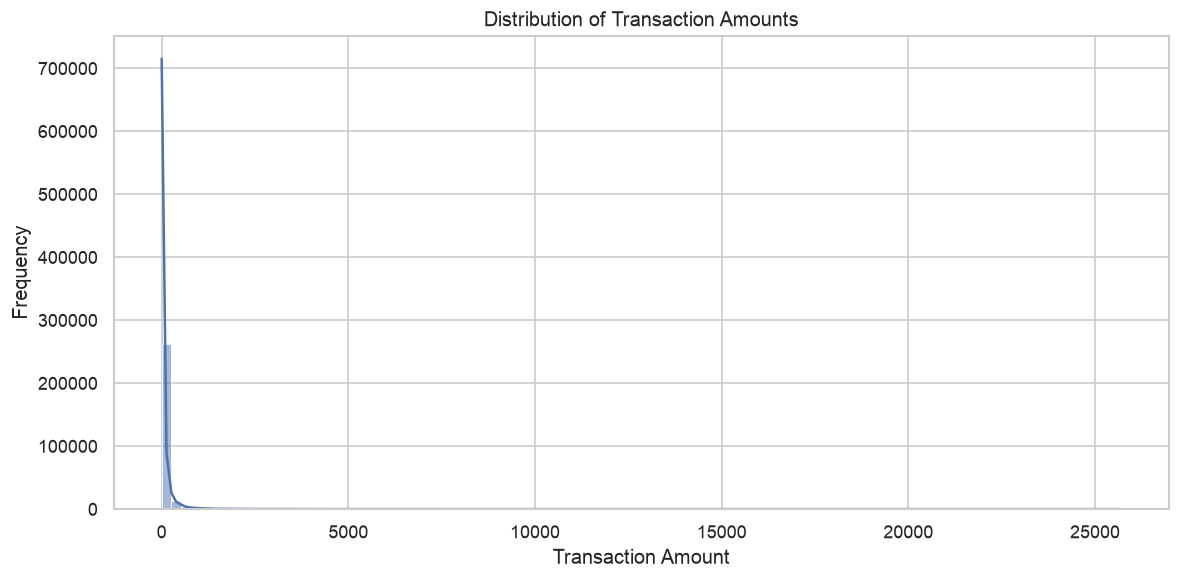

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    bins=100,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "amount_distribution.png")
plt.show()

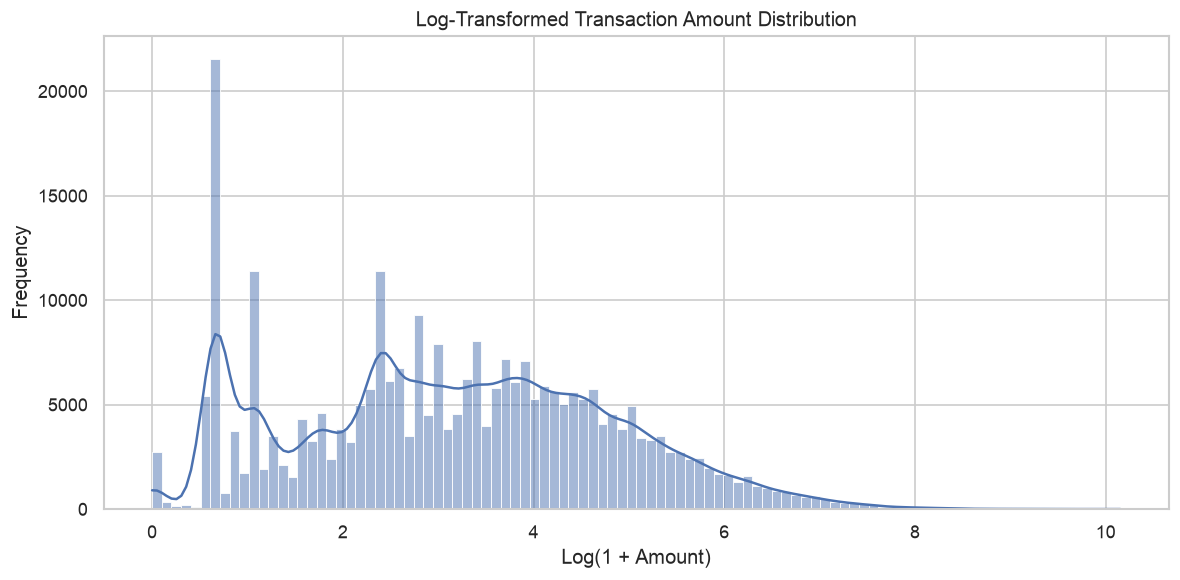

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df["Amount"]),
    bins=100,
    kde=True
)

plt.title("Log-Transformed Transaction Amount Distribution")
plt.xlabel("Log(1 + Amount)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "amount_log_distribution.png")
plt.show()

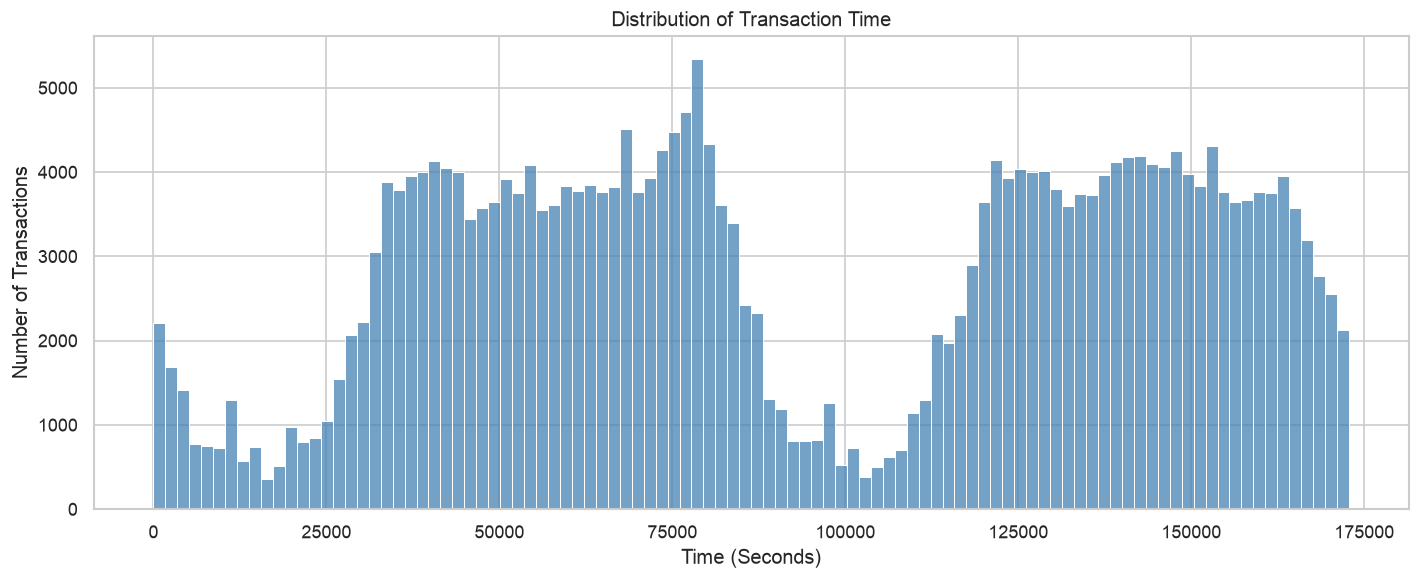

In [15]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Time",
    bins=100,
    color="steelblue"
)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time (Seconds)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "time_distribution.png")
plt.show()

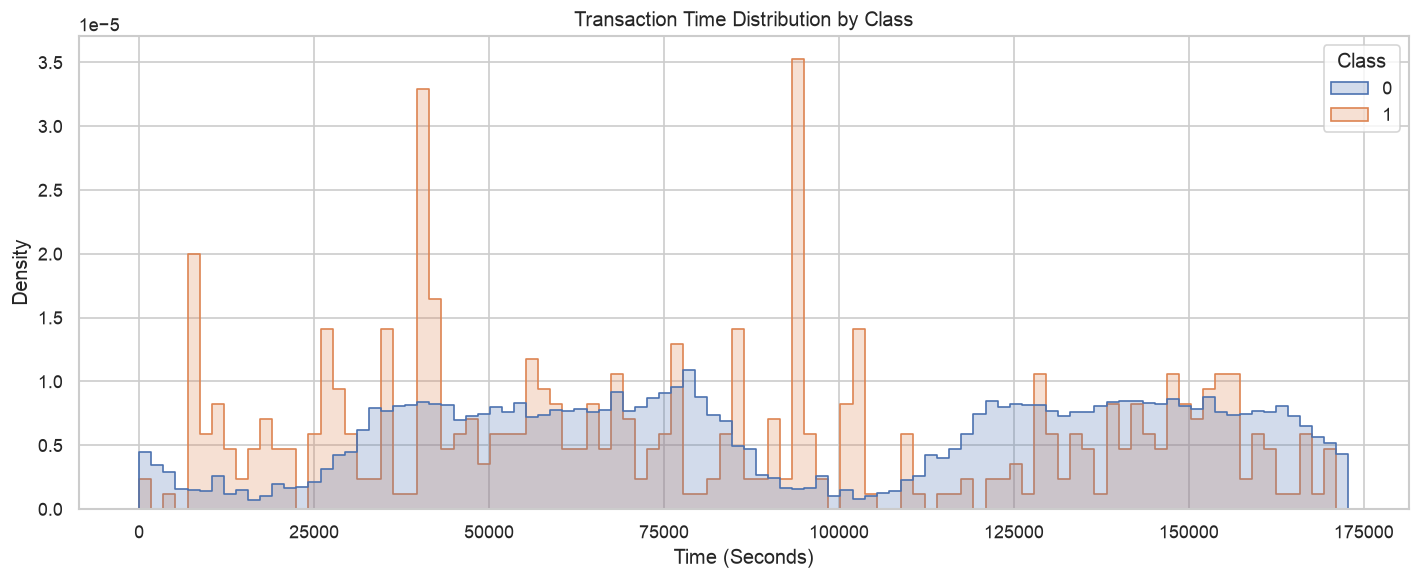

In [16]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Time (Seconds)")
plt.ylabel("Density")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "time_by_class.png")
plt.show()

In [17]:
time_stats = df.groupby("Class")["Time"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

display(time_stats)

,count,mean,median,std,min,max
Class,,,,,,
0,284315,94838.202258,84711.0,47484.015786,0.0,172792.0
1,492,80746.806911,75568.5,47835.365138,406.0,170348.0


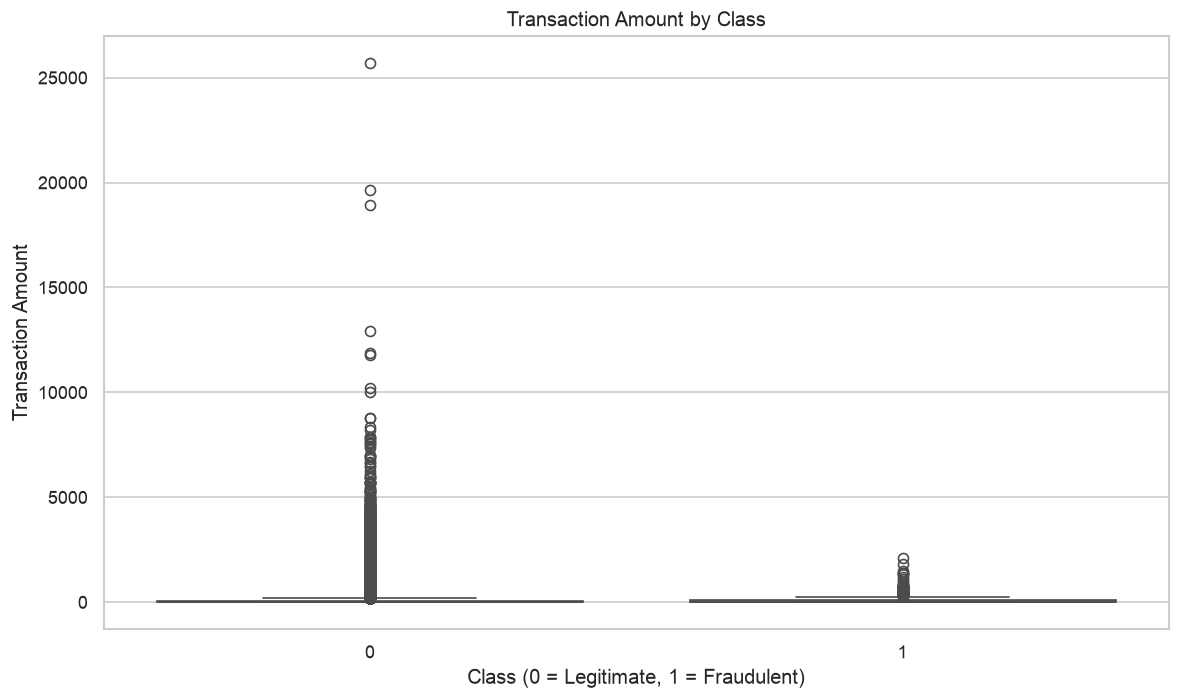

In [18]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Transaction Amount")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "amount_by_class_boxplot.png")
plt.show()

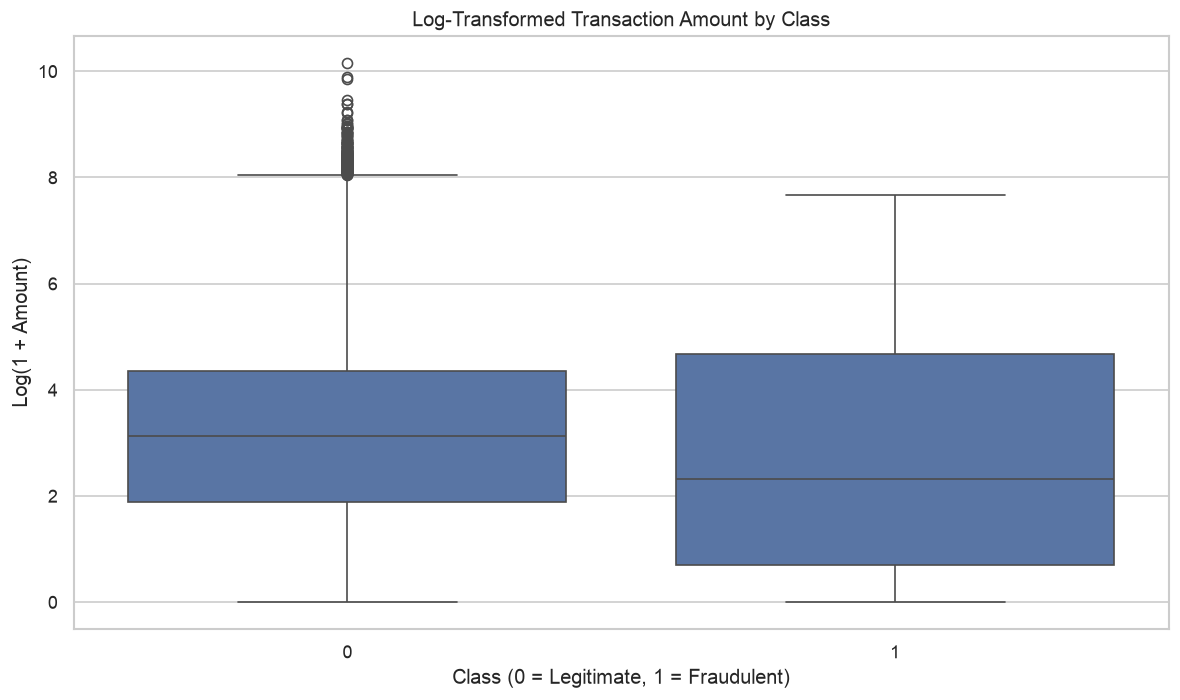

In [19]:
df["Log_Amount"] = np.log1p(df["Amount"])

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Log_Amount"
)

plt.title("Log-Transformed Transaction Amount by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Log(1 + Amount)")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "log_amount_by_class.png")
plt.show()

In [20]:
df["Time_Bin"] = pd.cut(
    df["Time"],
    bins=20
)

time_fraud_analysis = (
    df.groupby("Time_Bin", observed=False)
    .agg(
        total_transactions=("Class", "count"),
        fraudulent_transactions=("Class", "sum")
    )
)

time_fraud_analysis["fraud_rate_percent"] = (
    time_fraud_analysis["fraudulent_transactions"]
    / time_fraud_analysis["total_transactions"]
) * 100

display(time_fraud_analysis)

,total_transactions,fraudulent_transactions,fraud_rate_percent
Time_Bin,,,
"(-172.792, 8639.6]",6830,20,0.292826
"(8639.6, 17279.2]",3680,22,0.597826
"(17279.2, 25918.8]",4185,19,0.454002
"(25918.8, 34558.4]",12770,29,0.227095
"(34558.4, 43198.0]",19932,56,0.280955
"(43198.0, 51837.6]",18594,23,0.123696
"(51837.6, 60477.2]",18833,35,0.185844
"(60477.2, 69116.8]",19717,28,0.142009
"(69116.8, 77756.4]",21140,28,0.132450


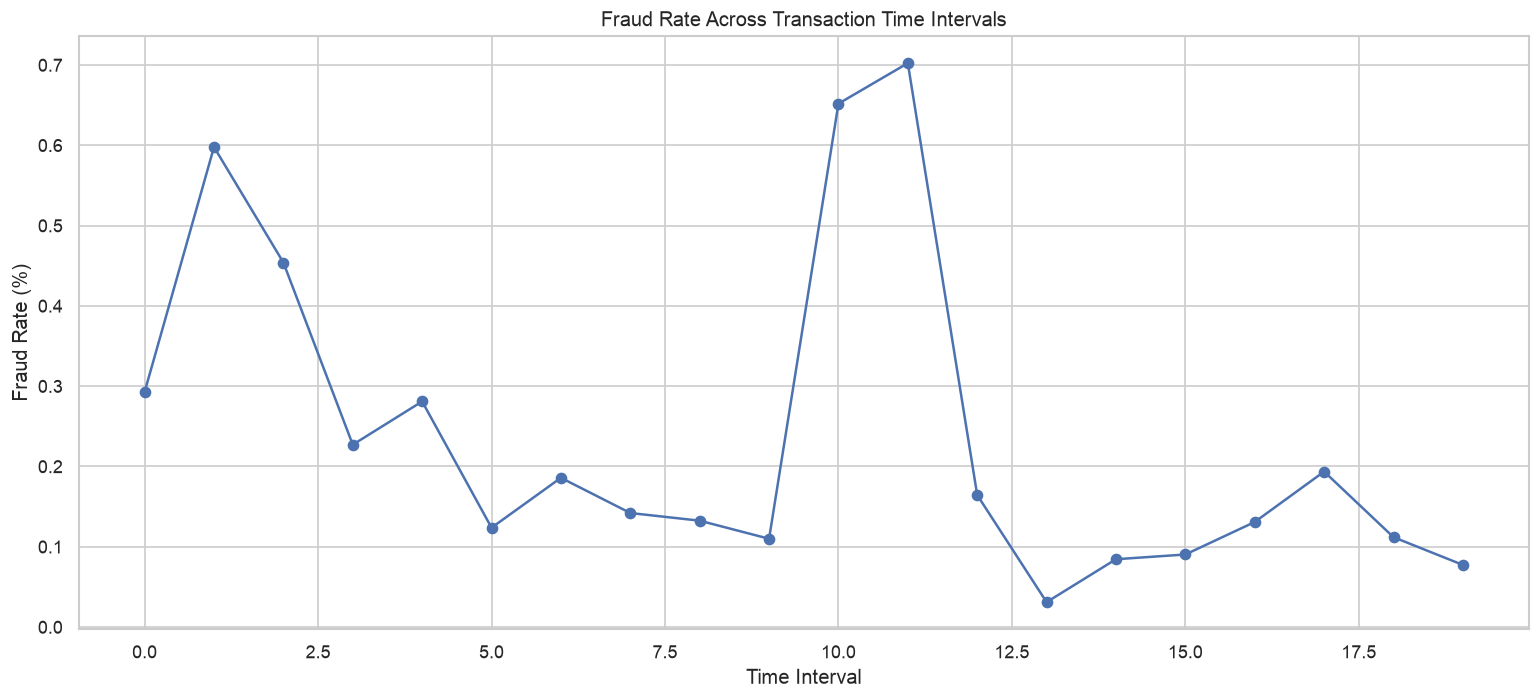

In [21]:
plt.figure(figsize=(13, 6))

plt.plot(
    range(len(time_fraud_analysis)),
    time_fraud_analysis["fraud_rate_percent"],
    marker="o"
)

plt.title("Fraud Rate Across Transaction Time Intervals")
plt.xlabel("Time Interval")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fraud_rate_over_time.png")
plt.show()

In [22]:
pca_features = [f"V{i}" for i in range(1, 29)]

print("Number of PCA features:", len(pca_features))

display(df[pca_features].describe().T)

Number of PCA features: 28


,count,mean,std,min,25%,50%,75%,max
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995
V10,284807.0,2.236957e-15,1.088850,-24.588262,-0.535426,-0.092917,0.453923,23.745136


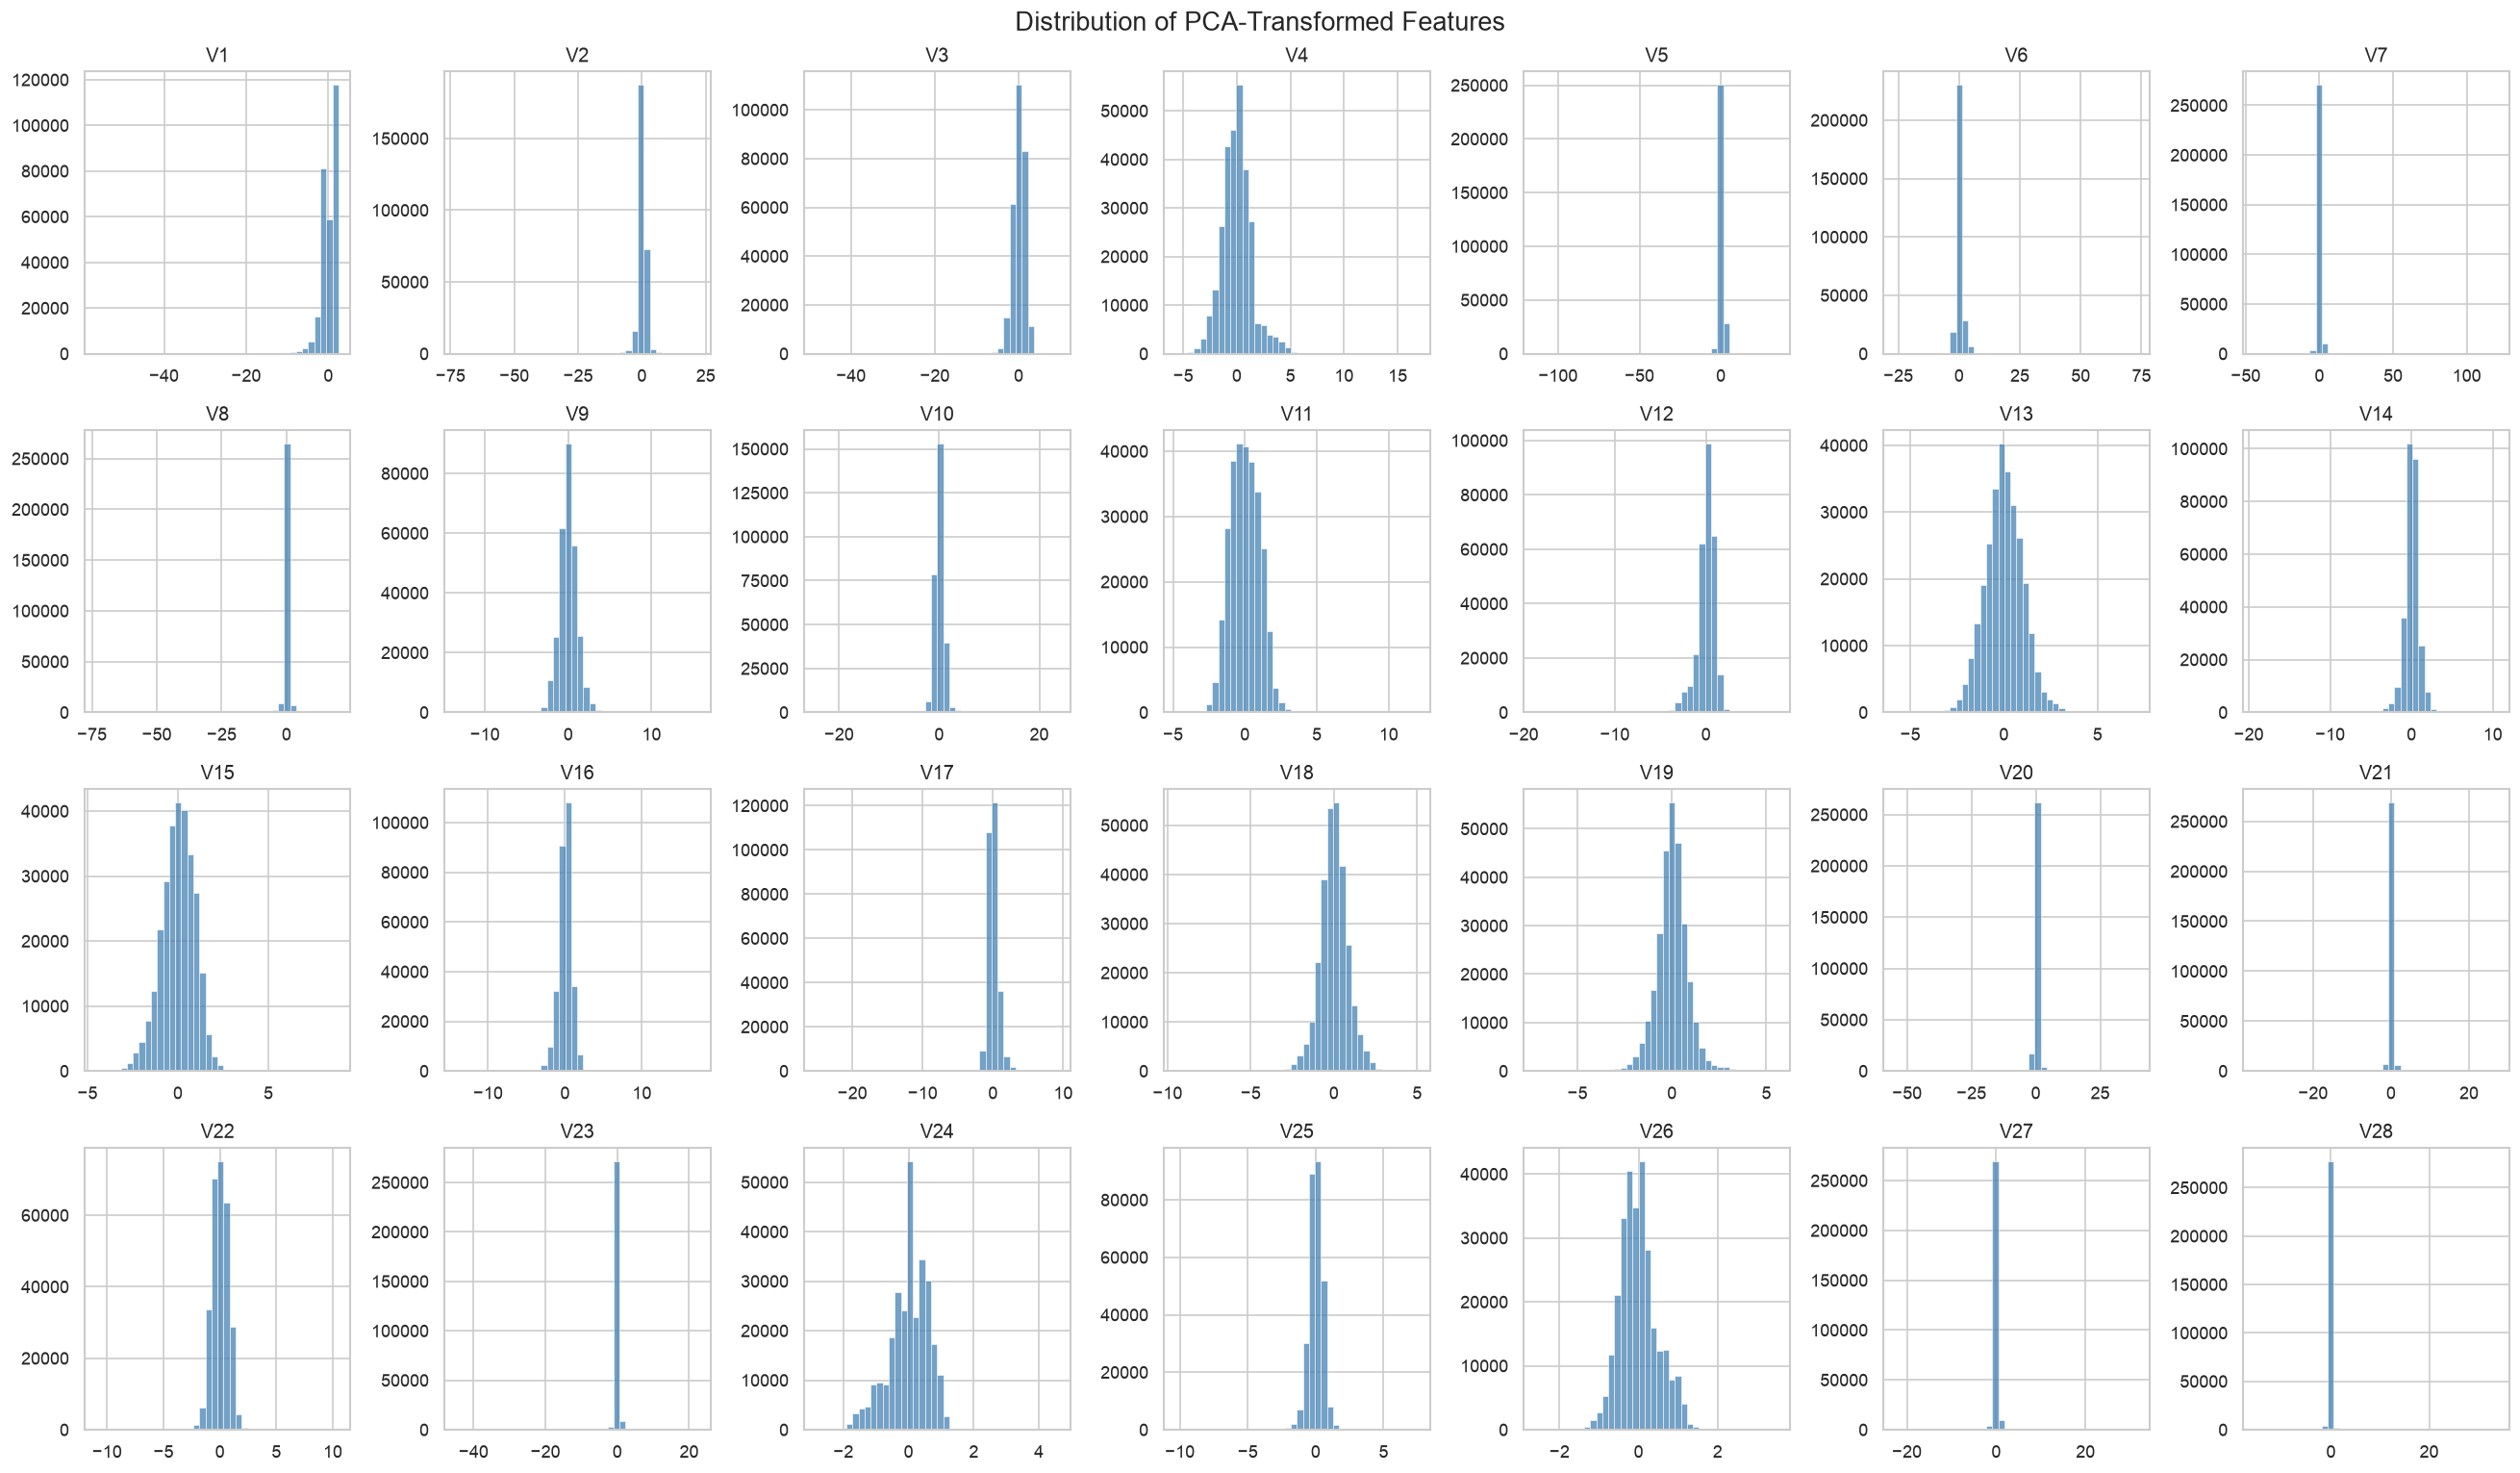

In [23]:
fig, axes = plt.subplots(4, 7, figsize=(22, 13))

for i, feature in enumerate(pca_features):

    ax = axes[i // 7, i % 7]

    sns.histplot(
        df[feature],
        bins=40,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle(
    "Distribution of PCA-Transformed Features",
    fontsize=16
)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "pca_feature_distributions.png")
plt.show()

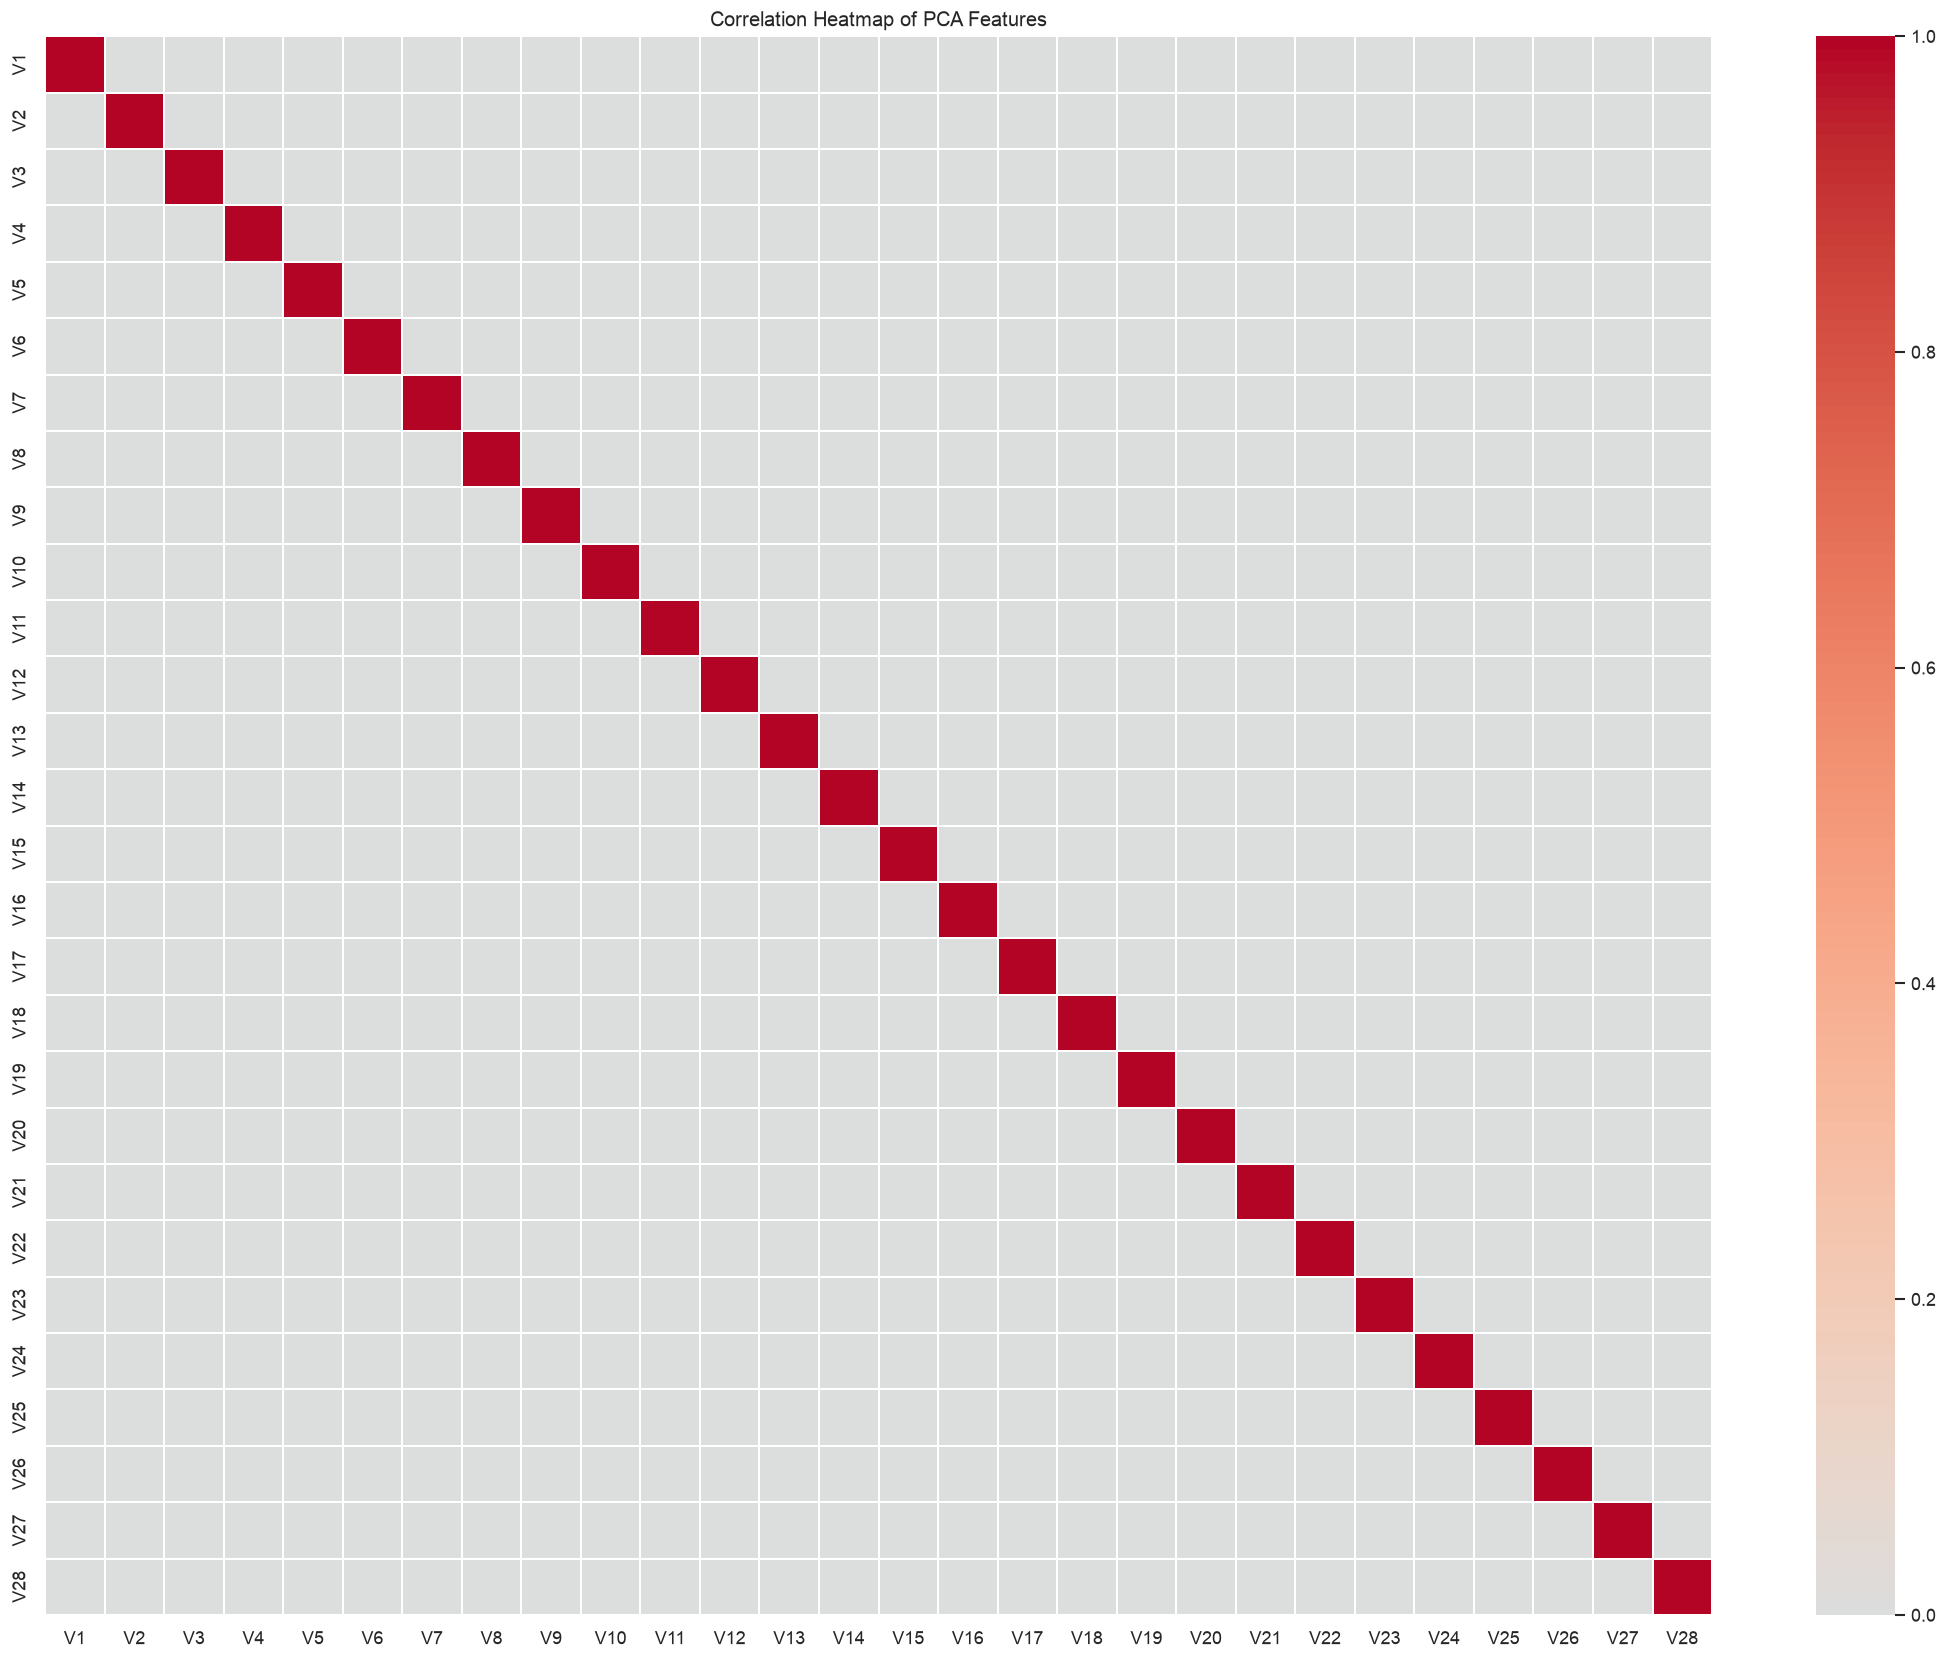

In [24]:
plt.figure(figsize=(18, 14))

correlation_matrix = df[pca_features].corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of PCA Features")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "pca_correlation_heatmap.png")
plt.show()

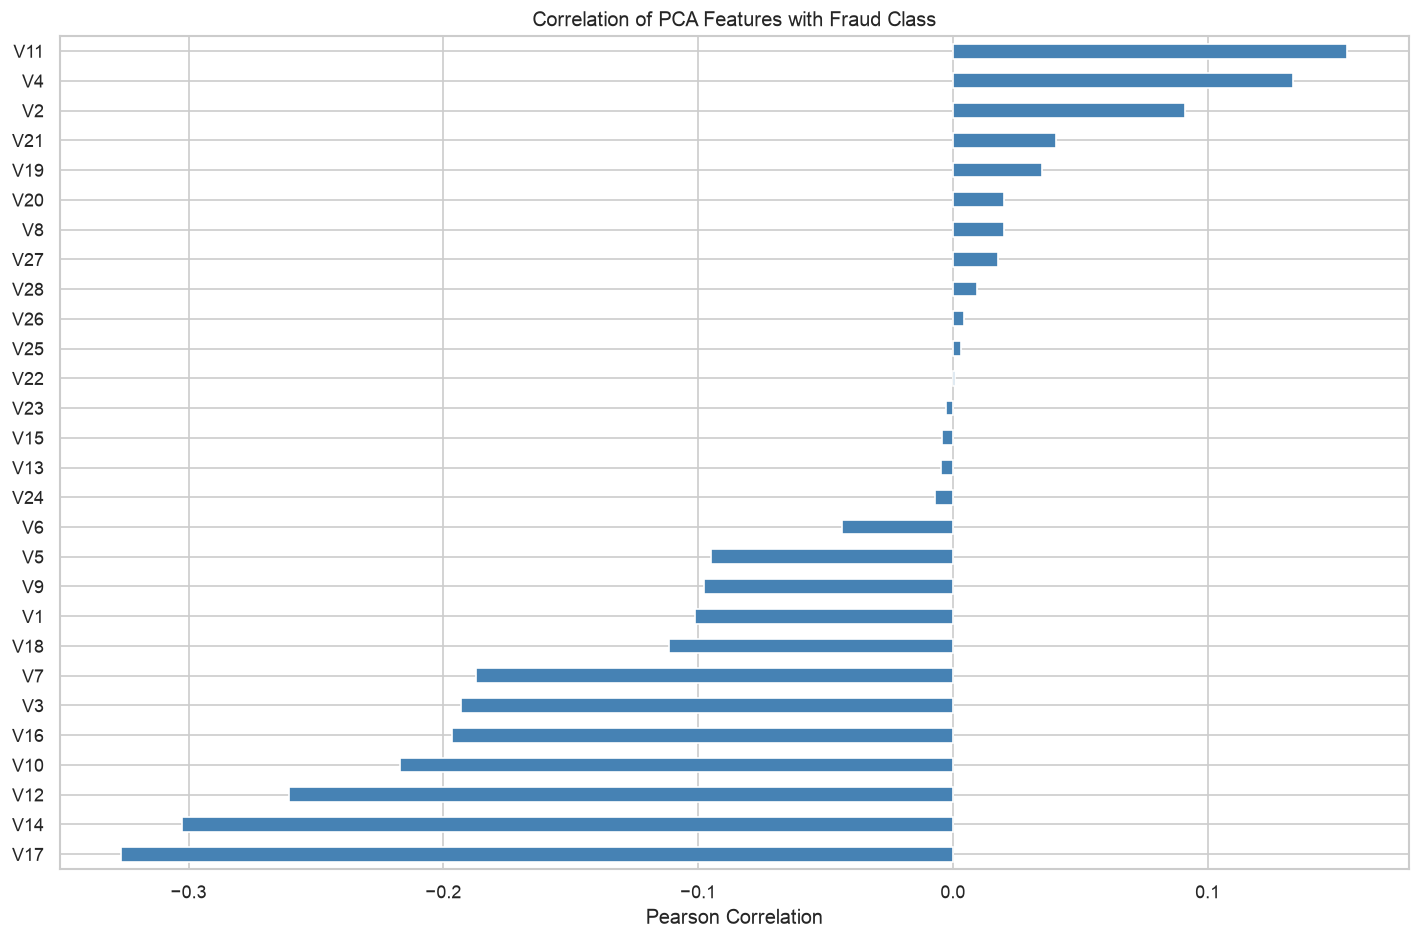

,Class_Correlation
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V18,-0.111485
V1,-0.101347
V9,-0.097733


In [25]:
feature_class_corr = (
    df[pca_features + ["Class"]]
    .corr()["Class"]
    .drop("Class")
    .sort_values()
)

plt.figure(figsize=(12, 8))

feature_class_corr.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Correlation of PCA Features with Fraud Class")
plt.xlabel("Pearson Correlation")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "feature_class_correlation.png")
plt.show()

display(feature_class_corr.to_frame("Class_Correlation"))

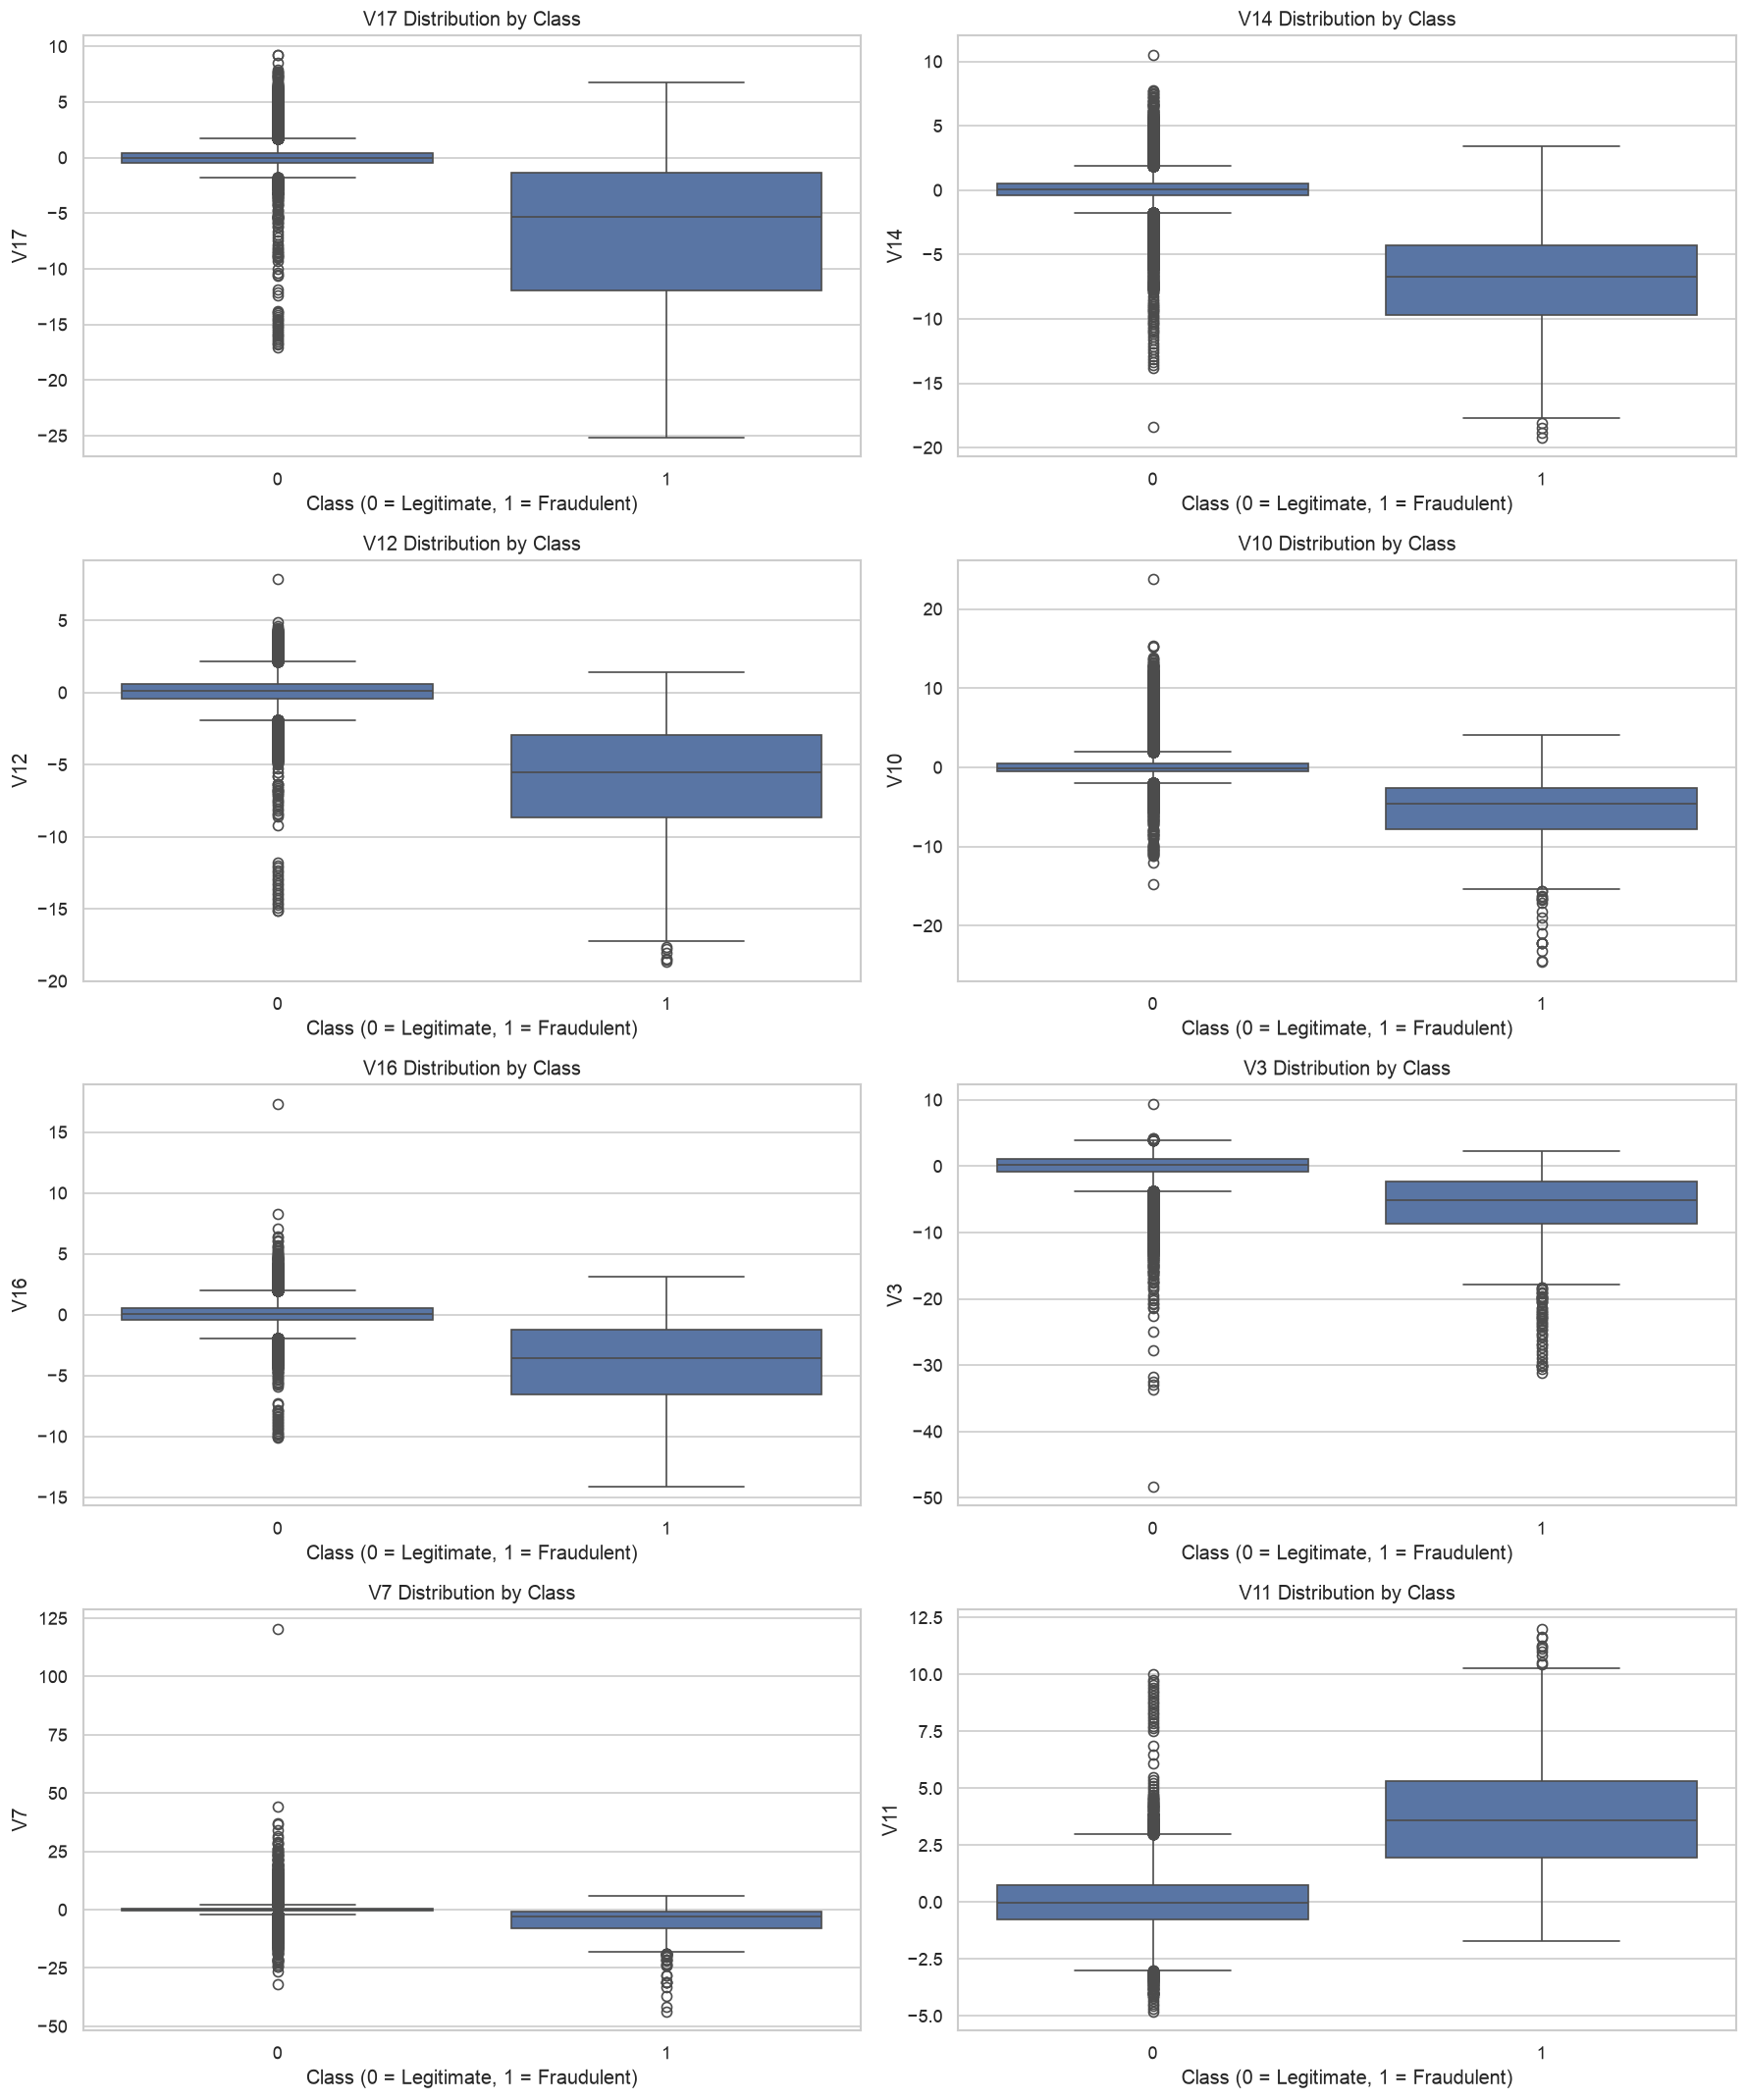

In [26]:
top_features = (
    feature_class_corr.abs()
    .sort_values(ascending=False)
    .head(8)
    .index
)

fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for i, feature in enumerate(top_features):

    ax = axes[i // 2, i % 2]

    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} Distribution by Class")
    ax.set_xlabel("Class (0 = Legitimate, 1 = Fraudulent)")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_features_by_class.png")
plt.show()

In [27]:
time_fraud_analysis["fraud_rate_percent"] = (
    time_fraud_analysis["fraud_rate_percent"].round(4)
)

display(
    time_fraud_analysis.sort_values(
        "fraud_rate_percent",
        ascending=False
    )
)

,total_transactions,fraudulent_transactions,fraud_rate_percent
Time_Bin,,,
"(95035.6, 103675.2]",3702,26,0.7023
"(86396.0, 95035.6]",6443,42,0.6519
"(8639.6, 17279.2]",3680,22,0.5978
"(17279.2, 25918.8]",4185,19,0.4540
"(-172.792, 8639.6]",6830,20,0.2928
"(34558.4, 43198.0]",19932,56,0.2810
"(25918.8, 34558.4]",12770,29,0.2271
"(146873.2, 155512.8]",20143,39,0.1936
"(51837.6, 60477.2]",18833,35,0.1858


In [28]:
feature_class_corr = (
    df[pca_features + ["Class"]]
    .corr()["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)

correlation_results = pd.DataFrame({
    "Feature": feature_class_corr.index,
    "Correlation": feature_class_corr.values,
    "Absolute_Correlation": feature_class_corr.abs().values
})

display(correlation_results)

,Feature,Correlation,Absolute_Correlation
0,V17,-0.326481,0.326481
1,V14,-0.302544,0.302544
2,V12,-0.260593,0.260593
3,V10,-0.216883,0.216883
4,V16,-0.196539,0.196539
5,V3,-0.192961,0.192961
6,V7,-0.187257,0.187257
7,V11,0.154876,0.154876
8,V4,0.133447,0.133447
9,V18,-0.111485,0.111485


In [29]:
feature_comparison = df.groupby("Class")[pca_features].agg(
    ["mean", "median", "std"]
)

display(feature_comparison)

V1                            V2                            V3  \
           mean    median       std      mean    median       std      mean   
Class                                                                         
0      0.008258  0.020023  1.929814 -0.006271  0.064070  1.636146  0.012171   
1     -4.771948 -2.342497  6.783687  3.623778  2.717869  4.291216 -7.033281   

                                 V4  ...       V25       V26            \
         median       std      mean  ...       std      mean    median   
Class                                ...                                 
0      0.182158  1.459429 -0.007860  ...  0.520673 -0.000089 -0.052227   
1     -5.075257  7.110937  4.542029  ...  0.797205  0.051648  0.004321   

                      V27                           V28                      
            std      mean    median       std      mean    median       std  
Class                                                                        
0      0.482241 -0.000295  0.001230  0.399847 -0.000131  0.011199  0.329570  
1      0.471679  0.170575  0.394926  1.376766  0.075667  0.146344  0.547291  

[2 rows x 84 columns]

In [30]:
class_means = df.groupby("Class")[pca_features].mean()

mean_difference = (
    class_means.loc[1] - class_means.loc[0]
)

mean_difference = mean_difference.sort_values(
    key=abs,
    ascending=False
)

display(mean_difference.to_frame("Mean_Difference"))

,Mean_Difference
V3,-7.045452
V14,-6.983787
V17,-6.677371
V12,-6.270225
V10,-5.686707
V7,-5.578368
V1,-4.780206
V4,4.549889
V16,-4.147110
V11,3.806749


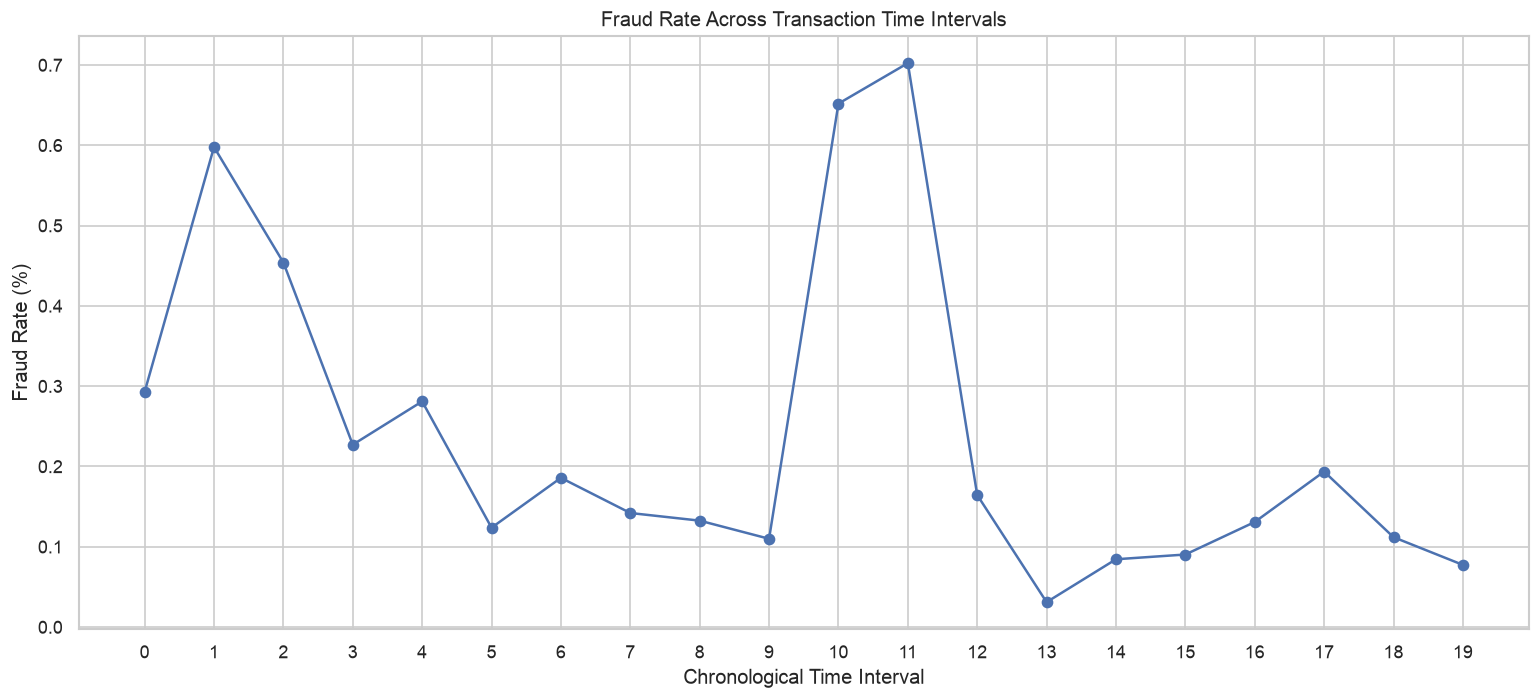

In [31]:
plt.figure(figsize=(13, 6))

plt.plot(
    range(len(time_fraud_analysis)),
    time_fraud_analysis["fraud_rate_percent"],
    marker="o"
)

plt.xticks(range(len(time_fraud_analysis)))

plt.title("Fraud Rate Across Transaction Time Intervals")
plt.xlabel("Chronological Time Interval")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fraud_rate_over_time.png")
plt.show()

In [32]:
duplicate_groups = (
    df.groupby(list(df.columns), dropna=False)
    .size()
    .reset_index(name="frequency")
)

duplicate_groups = duplicate_groups[
    duplicate_groups["frequency"] > 1
]

print("Unique duplicate groups:", len(duplicate_groups))

print("\nGroup frequencies:")
print(duplicate_groups["frequency"].value_counts().sort_index())

print("\nDuplicate groups by class:")
display(
    duplicate_groups.groupby("Class")["frequency"].agg(
        ["count", "sum"]
    )
)

Unique duplicate groups: 773

Group frequencies:
frequency
2     611
3      66
4      81
5      10
6       1
9       2
18      2
Name: count, dtype: int64

Duplicate groups by class:


,count,sum
Class,,
0,760,1822
1,13,32


In [33]:
groups = pd.util.hash_pandas_object(
    df,
    index=False
).to_numpy()

print("Total rows:", len(df))
print("Unique groups:", len(np.unique(groups)))

Total rows: 284807
Unique groups: 283726
